Little 5min | rows: 2918 | duration: 304.75 seconds | approx rate: 9.58 Hz
Little 10min | rows: 60745 | duration: 607.72 seconds | approx rate: 99.96 Hz
Little 15min_old | rows: 908164 | duration: 908.58 seconds | approx rate: 999.54 Hz
Little 15min_new | rows: 947958 | duration: 948.36 seconds | approx rate: 999.58 Hz

Saved: ..\EMG Recordings\little_finger_45mins_combined.csv
Total rows: 1919785
Total duration: 2769.52 seconds

Middle 5min | rows: 2928 | duration: 305.74 seconds | approx rate: 9.58 Hz
Middle 10min | rows: 61789 | duration: 618.18 seconds | approx rate: 99.95 Hz
Middle 15min_old | rows: 1021625 | duration: 1021.97 seconds | approx rate: 999.66 Hz
Middle 15min_new | rows: 903036 | duration: 902.88 seconds | approx rate: 1000.17 Hz

Saved: ..\EMG Recordings\middle_finger_45mins_combined.csv
Total rows: 1989378
Total duration: 2848.88 seconds

Ring 5min | rows: 3149 | duration: 329.09 seconds | approx rate: 9.57 Hz
Ring 10min | rows: 60905 | duration: 609.33 seconds | ap

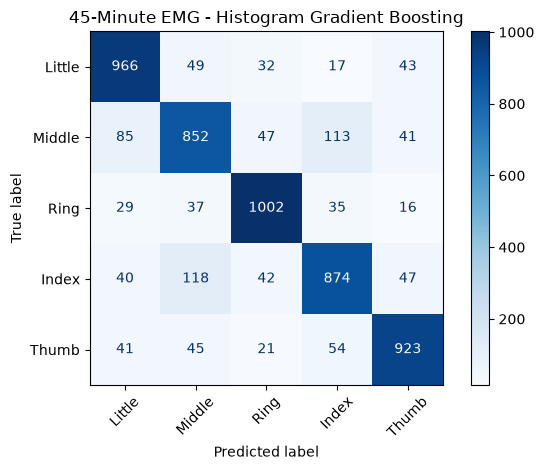

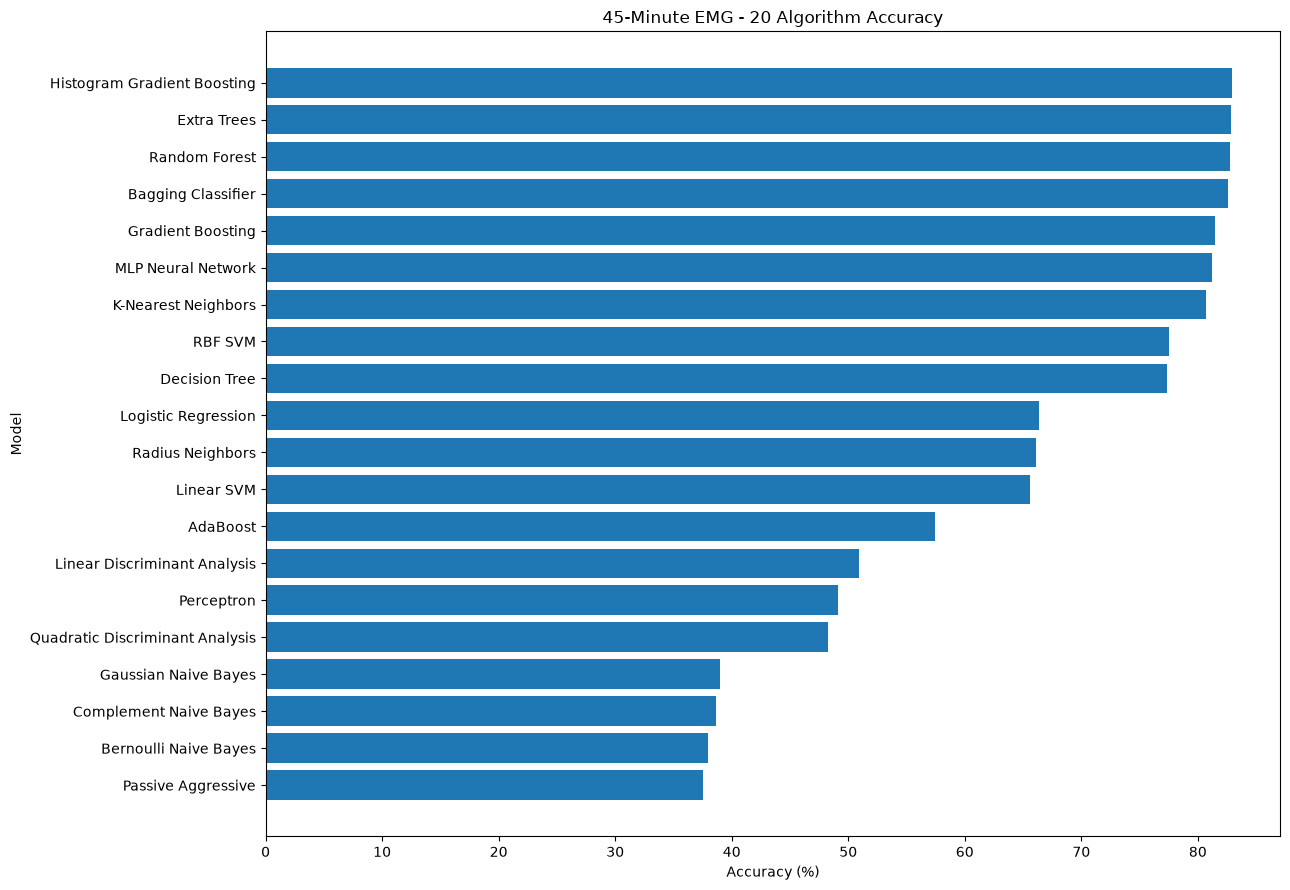

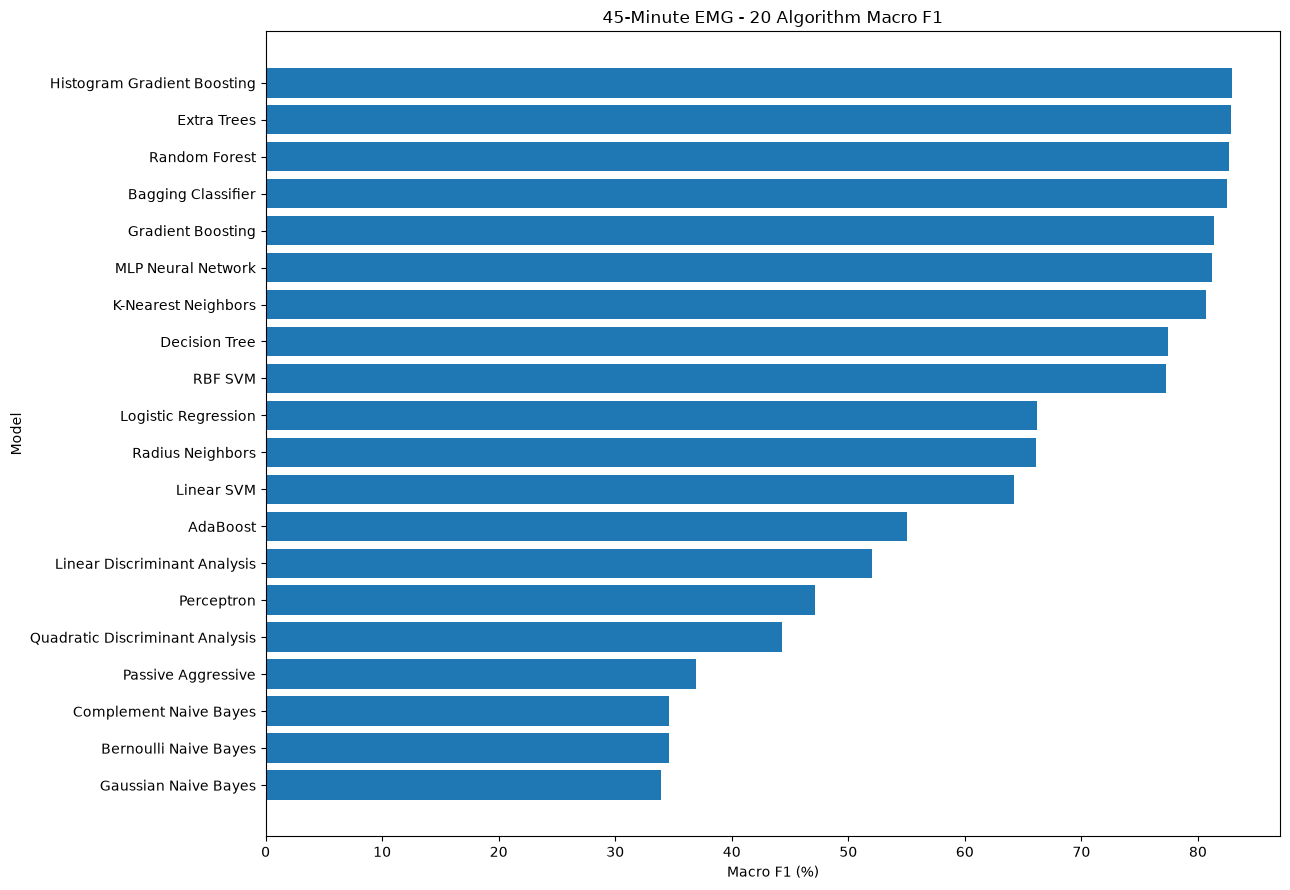

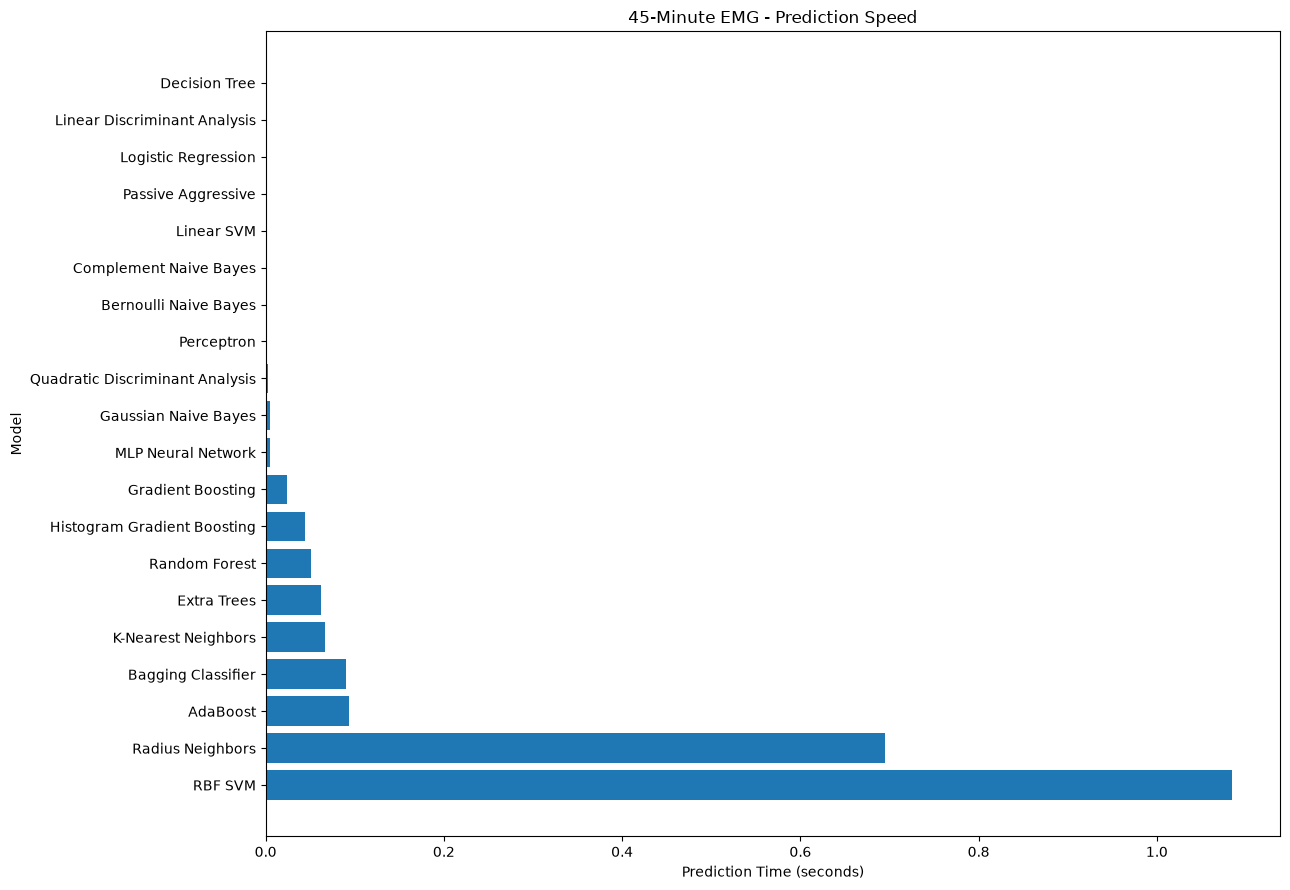


Accuracy / Speed Efficiency

                          Model  Accuracy  Macro F1  Training Time  Prediction Time  Total Time  Efficiency Score
         Complement Naive Bayes  0.386425  0.346544       0.004673         0.001046    0.005719         57.513968
          Bernoulli Naive Bayes  0.379960  0.346369       0.005604         0.001387    0.006991         47.547365
   Linear Discriminant Analysis  0.509248  0.519929       0.012208         0.000827    0.013035         36.283603
Quadratic Discriminant Analysis  0.482313  0.443316       0.009384         0.003022    0.012407         35.975237
           Gaussian Naive Bayes  0.390016  0.339676       0.007074         0.004368    0.011442         31.347749
                     Perceptron  0.491112  0.471547       0.026611         0.001851    0.028463         16.668924
            K-Nearest Neighbors  0.806967  0.806652       0.003470         0.066406    0.069876         11.385603
             Passive Aggressive  0.374933  0.369697       

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time
import warnings

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import (
    LogisticRegression,
    Perceptron,
    PassiveAggressiveClassifier
)

from sklearn.neighbors import (
    KNeighborsClassifier,
    RadiusNeighborsClassifier
)

from sklearn.svm import (
    SVC,
    LinearSVC
)

from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier,
    AdaBoostClassifier,
    BaggingClassifier,
    GradientBoostingClassifier
)

from sklearn.naive_bayes import (
    GaussianNB,
    BernoulliNB,
    ComplementNB
)

from sklearn.neural_network import MLPClassifier

from sklearn.discriminant_analysis import (
    LinearDiscriminantAnalysis,
    QuadraticDiscriminantAnalysis
)

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")

data_folder = Path("../EMG Recordings")

files = {
    "Little": {
        "5min": data_folder / "little finger emg_2sensor_20260922_123054.csv",
        "10min": data_folder / "little_finger 10mins.csv",
        "15min_old": data_folder / "little_finger_15mins.csv",
        "15min_new": data_folder / "little new 15mins.csv"
    },

    "Middle": {
        "5min": data_folder / "middle finger emg_2sensor_20260922_124337.csv",
        "10min": data_folder / "middle_finger_10mins.csv",
        "15min_old": data_folder / "middle_finger_15mins.csv",
        "15min_new": data_folder / "middle new 15mins.csv"
    },

    "Ring": {
        "5min": data_folder / "Ring finger emg_2sensor_20260922_123712.csv",
        "10min": data_folder / "ring_finger_10mins.csv",
        "15min_old": data_folder / "ring_finger_15mins.csv",
        "15min_new": data_folder / "ring new 15mins.csv"
    },

    "Index": {
        "5min": data_folder / "index emg_2sensor_20260922_124922.csv",
        "10min": data_folder / "index_finger_10mins.csv",
        "15min_old": data_folder / "index_finger_15mins.csv",
        "15min_new": data_folder / "index new 15mins.csv"
    },

    "Thumb": {
        "5min": data_folder / "Thumb finger emg_2sensor_20260922_125701.csv",
        "10min": data_folder / "thumb_finger_10mins.csv",
        "15min_old": data_folder / "thumb_finger_15mins.csv",
        "15min_new": data_folder / "thumbs new 15mins.csv"
    }
}

session_order = [
    "5min",
    "10min",
    "15min_old",
    "15min_new"
]

combined_files = {}

for finger, finger_files in files.items():

    combined_parts = []
    cumulative_time = 0.0

    for session_name in session_order:

        file_path = finger_files[
            session_name
        ]

        if not file_path.exists():

            raise FileNotFoundError(
                f"File not found: {file_path}"
            )

        data = pd.read_csv(
            file_path
        )

        required_columns = [
            "time_s",
            "emg1",
            "emg2"
        ]

        missing_columns = [
            column
            for column in required_columns
            if column not in data.columns
        ]

        if missing_columns:

            raise ValueError(
                f"{file_path} missing columns: "
                f"{missing_columns}"
            )

        data = data[
            required_columns
        ].copy()

        for column in required_columns:

            data[column] = pd.to_numeric(
                data[column],
                errors="coerce"
            )

        data = data.dropna().reset_index(
            drop=True
        )

        if len(data) < 2:

            raise ValueError(
                f"Not enough data in {file_path}"
            )

        data["session"] = session_name

        data["session_time_s"] = (
            data["time_s"]
            -
            data["time_s"].iloc[0]
        )

        differences = np.diff(
            data["session_time_s"].values
        )

        positive_differences = differences[
            differences > 0
        ]

        if len(positive_differences) > 0:

            time_step = np.median(
                positive_differences
            )

        else:

            time_step = 0.001

        data["combined_time_s"] = (
            data["session_time_s"]
            +
            cumulative_time
        )

        cumulative_time = (
            data["combined_time_s"].iloc[-1]
            +
            time_step
        )

        combined_parts.append(
            data
        )

        duration = (
            data["session_time_s"].iloc[-1]
        )

        sample_rate = (
            len(data)
            /
            duration
            if duration > 0
            else 0
        )

        print(
            finger,
            session_name,
            "| rows:",
            len(data),
            "| duration:",
            round(duration, 2),
            "seconds",
            "| approx rate:",
            round(sample_rate, 2),
            "Hz"
        )

    combined_data = pd.concat(
        combined_parts,
        ignore_index=True
    )

    output_file = (
        data_folder
        /
        f"{finger.lower()}_finger_45mins_combined.csv"
    )

    combined_data.to_csv(
        output_file,
        index=False
    )

    combined_files[
        finger
    ] = output_file

    print(
        "\nSaved:",
        output_file
    )

    print(
        "Total rows:",
        len(combined_data)
    )

    print(
        "Total duration:",
        round(
            combined_data[
                "combined_time_s"
            ].iloc[-1],
            2
        ),
        "seconds\n"
    )


def calculate_statistics(values):

    values = np.asarray(
        values,
        dtype=float
    )

    mean_value = np.mean(
        values
    )

    median_value = np.median(
        values
    )

    minimum_value = np.min(
        values
    )

    maximum_value = np.max(
        values
    )

    standard_deviation = np.std(
        values
    )

    variance_value = np.var(
        values
    )

    value_range = (
        maximum_value
        -
        minimum_value
    )

    rms_value = np.sqrt(
        np.mean(
            values ** 2
        )
    )

    mean_absolute_value = np.mean(
        np.abs(
            values
        )
    )

    if len(values) > 1:

        normalized_waveform_length = (
            np.sum(
                np.abs(
                    np.diff(
                        values
                    )
                )
            )
            /
            (
                len(values)
                -
                1
            )
        )

    else:

        normalized_waveform_length = 0.0

    return [
        mean_value,
        median_value,
        minimum_value,
        maximum_value,
        standard_deviation,
        variance_value,
        value_range,
        rms_value,
        mean_absolute_value,
        normalized_waveform_length
    ]


statistic_names = [
    "Mean",
    "Median",
    "Minimum",
    "Maximum",
    "Standard_Deviation",
    "Variance",
    "Range",
    "RMS",
    "Mean_Absolute_Value",
    "Normalized_Waveform_Length"
]

feature_names = []

for statistic in statistic_names:

    feature_names.append(
        f"EMG1_{statistic}"
    )

for statistic in statistic_names:

    feature_names.append(
        f"EMG2_{statistic}"
    )


def create_time_windows(
    data,
    window_seconds=1.0
):

    features = []
    sessions = []

    for session_name in session_order:

        session_data = data[
            data["session"]
            ==
            session_name
        ].copy()

        if len(session_data) == 0:

            continue

        session_data = session_data.sort_values(
            "session_time_s"
        ).reset_index(
            drop=True
        )

        duration = session_data[
            "session_time_s"
        ].iloc[-1]

        number_of_windows = int(
            duration
            //
            window_seconds
        )

        for window_number in range(
            number_of_windows
        ):

            start_time = (
                window_number
                *
                window_seconds
            )

            end_time = (
                start_time
                +
                window_seconds
            )

            window = session_data[
                (
                    session_data[
                        "session_time_s"
                    ]
                    >=
                    start_time
                )
                &
                (
                    session_data[
                        "session_time_s"
                    ]
                    <
                    end_time
                )
            ]

            if len(window) < 2:

                continue

            emg1_statistics = calculate_statistics(
                window[
                    "emg1"
                ].values
            )

            emg2_statistics = calculate_statistics(
                window[
                    "emg2"
                ].values
            )

            window_features = np.concatenate(
                [
                    emg1_statistics,
                    emg2_statistics
                ]
            )

            features.append(
                window_features
            )

            sessions.append(
                session_name
            )

    return (
        np.array(
            features
        ),
        np.array(
            sessions
        )
    )


emg_features = []
finger_labels = []
session_labels = []

for finger, file_path in combined_files.items():

    data = pd.read_csv(
        file_path
    )

    finger_features, finger_sessions = (
        create_time_windows(
            data,
            window_seconds=1.0
        )
    )

    print(
        finger,
        "windows:",
        len(
            finger_features
        )
    )

    for feature_vector, session_name in zip(
        finger_features,
        finger_sessions
    ):

        emg_features.append(
            feature_vector
        )

        finger_labels.append(
            finger
        )

        session_labels.append(
            session_name
        )

emg_features = np.array(
    emg_features
)

finger_labels = np.array(
    finger_labels
)

session_labels = np.array(
    session_labels
)


print("\nDataset Information")

print(
    "Features:",
    emg_features.shape
)

print(
    "Labels:",
    finger_labels.shape
)

print(
    "Features per window:",
    emg_features.shape[1]
)

print(
    "\nFinger Distribution:"
)

print(
    pd.Series(
        finger_labels
    ).value_counts()
)

print(
    "\nSession Distribution:"
)

print(
    pd.Series(
        session_labels
    ).value_counts()
)


(
    train_features,
    test_features,
    train_labels,
    test_labels,
    train_sessions,
    test_sessions

) = train_test_split(

    emg_features,
    finger_labels,
    session_labels,

    train_size=0.60,
    test_size=0.40,

    random_state=42,
    shuffle=True,

    stratify=finger_labels
)


print(
    "\nTraining:",
    train_features.shape
)

print(
    "Testing:",
    test_features.shape
)

print(
    "\nTraining Sessions:"
)

print(
    pd.Series(
        train_sessions
    ).value_counts()
)

print(
    "\nTesting Sessions:"
)

print(
    pd.Series(
        test_sessions
    ).value_counts()
)


random_index = np.random.randint(
    0,
    len(
        test_features
    )
)

random_features = test_features[
    random_index
]

random_label = test_labels[
    random_index
]

random_session = test_sessions[
    random_index
]


print(
    "\nRandom Test Window"
)

print(
    "Finger:",
    random_label
)

print(
    "Session:",
    random_session
)

print(
    f"\n{'Statistic':<30}"
    f"{'EMG1':>15}"
    f"{'EMG2':>15}"
)

for i in range(
    len(
        statistic_names
    )
):

    print(
        f"{statistic_names[i]:<30}"
        f"{random_features[i]:>15.4f}"
        f"{random_features[i + 10]:>15.4f}"
    )


models = {

    "Logistic Regression":

        Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                LogisticRegression(
                    max_iter=3000,
                    random_state=42
                )
            )
        ]),

    "K-Nearest Neighbors":

        Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                KNeighborsClassifier(
                    n_neighbors=7,
                    weights="distance",
                    n_jobs=-1
                )
            )
        ]),

    "RBF SVM":

        Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                SVC(
                    kernel="rbf",
                    C=3.0,
                    gamma="scale"
                )
            )
        ]),

    "Linear SVM":

        Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                LinearSVC(
                    C=1.0,
                    max_iter=5000,
                    random_state=42
                )
            )
        ]),

    "Decision Tree":

        DecisionTreeClassifier(
            min_samples_leaf=2,
            random_state=42
        ),

    "Random Forest":

        RandomForestClassifier(
            n_estimators=250,
            max_features="sqrt",
            random_state=42,
            n_jobs=-1
        ),

    "Extra Trees":

        ExtraTreesClassifier(
            n_estimators=250,
            max_features="sqrt",
            random_state=42,
            n_jobs=-1
        ),

    "Histogram Gradient Boosting":

        HistGradientBoostingClassifier(
            learning_rate=0.08,
            max_iter=200,
            max_leaf_nodes=31,
            random_state=42
        ),

    "Gaussian Naive Bayes":

        Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                GaussianNB()
            )
        ]),

    "MLP Neural Network":

        Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                MLPClassifier(
                    hidden_layer_sizes=(
                        128,
                        64
                    ),
                    activation="relu",
                    max_iter=300,
                    early_stopping=True,
                    validation_fraction=0.10,
                    n_iter_no_change=15,
                    random_state=42
                )
            )
        ]),

    "Linear Discriminant Analysis":

        Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                LinearDiscriminantAnalysis(
                    solver="lsqr",
                    shrinkage="auto"
                )
            )
        ]),

    "Quadratic Discriminant Analysis":

        Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                QuadraticDiscriminantAnalysis(
                    reg_param=0.2
                )
            )
        ]),

    "Perceptron":

        Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                Perceptron(
                    max_iter=2000,
                    tol=1e-3,
                    random_state=42
                )
            )
        ]),

    "Passive Aggressive":

        Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                PassiveAggressiveClassifier(
                    C=1.0,
                    max_iter=2000,
                    tol=1e-3,
                    random_state=42
                )
            )
        ]),

    "Bernoulli Naive Bayes":

        Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                BernoulliNB(
                    alpha=1.0
                )
            )
        ]),

    "Complement Naive Bayes":

        Pipeline([
            (
                "scaler",
                MinMaxScaler(
                    clip=True
                )
            ),
            (
                "model",
                ComplementNB(
                    alpha=1.0
                )
            )
        ]),

    "AdaBoost":

        AdaBoostClassifier(
            n_estimators=150,
            learning_rate=0.5,
            random_state=42
        ),

    "Bagging Classifier":

        BaggingClassifier(
            n_estimators=100,
            max_samples=0.8,
            max_features=1.0,
            n_jobs=-1,
            random_state=42
        ),

    "Gradient Boosting":

        GradientBoostingClassifier(
            n_estimators=150,
            learning_rate=0.08,
            max_depth=3,
            random_state=42
        ),

    "Radius Neighbors":

        Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                RadiusNeighborsClassifier(
                    radius=5.0,
                    weights="distance",
                    outlier_label="most_frequent",
                    n_jobs=-1
                )
            )
        ])
}


results = []
trained_models = {}
model_predictions = {}


print(
    "\nTraining 20 Models"
)


for number, (
    model_name,
    model
) in enumerate(
    models.items(),
    start=1
):

    print(
        f"\n[{number}/20] "
        f"{model_name}"
    )

    try:

        training_start = time.perf_counter()

        model.fit(
            train_features,
            train_labels
        )

        training_time = (
            time.perf_counter()
            -
            training_start
        )

        prediction_start = time.perf_counter()

        predictions = model.predict(
            test_features
        )

        prediction_time = (
            time.perf_counter()
            -
            prediction_start
        )

        accuracy = accuracy_score(
            test_labels,
            predictions
        )

        balanced_accuracy = balanced_accuracy_score(
            test_labels,
            predictions
        )

        precision = precision_score(
            test_labels,
            predictions,
            average="macro",
            zero_division=0
        )

        recall = recall_score(
            test_labels,
            predictions,
            average="macro",
            zero_division=0
        )

        macro_f1 = f1_score(
            test_labels,
            predictions,
            average="macro",
            zero_division=0
        )

        weighted_f1 = f1_score(
            test_labels,
            predictions,
            average="weighted",
            zero_division=0
        )

        total_time = (
            training_time
            +
            prediction_time
        )

        results.append(
            {
                "Model":
                    model_name,

                "Accuracy":
                    accuracy,

                "Balanced Accuracy":
                    balanced_accuracy,

                "Macro Precision":
                    precision,

                "Macro Recall":
                    recall,

                "Macro F1":
                    macro_f1,

                "Weighted F1":
                    weighted_f1,

                "Training Time":
                    training_time,

                "Prediction Time":
                    prediction_time,

                "Total Time":
                    total_time
            }
        )

        trained_models[
            model_name
        ] = model

        model_predictions[
            model_name
        ] = predictions

        print(
            f"Accuracy: "
            f"{accuracy * 100:.4f}%"
        )

        print(
            f"Macro F1: "
            f"{macro_f1 * 100:.4f}%"
        )

        print(
            f"Training: "
            f"{training_time:.4f}s"
        )

        print(
            f"Prediction: "
            f"{prediction_time:.4f}s"
        )

    except Exception as error:

        print(
            "FAILED:",
            error
        )


results = pd.DataFrame(
    results
)

results = results.sort_values(
    by=[
        "Accuracy",
        "Macro F1"
    ],
    ascending=False
).reset_index(
    drop=True
)

results.insert(
    0,
    "Rank",
    np.arange(
        1,
        len(
            results
        ) + 1
    )
)

results["Efficiency Score"] = (
    results["Accuracy"]
    /
    (
        results["Total Time"]
        +
        0.001
    )
)


display_results = results.copy()


for column in [
    "Accuracy",
    "Balanced Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1",
    "Weighted F1"
]:

    display_results[
        column
    ] *= 100


print(
    "\n45-Minute EMG 20-Algorithm Comparison\n"
)


print(
    display_results.to_string(
        index=False,
        float_format=lambda value:
            f"{value:.4f}"
    )
)


results.to_csv(
    "45min_20_algorithm_comparison.csv",
    index=False
)


best_model_name = results.iloc[
    0
]["Model"]

best_model = trained_models[
    best_model_name
]

best_predictions = model_predictions[
    best_model_name
]


print(
    "\nBest Model:",
    best_model_name
)

print(
    f"Accuracy: "
    f"{results.iloc[0]['Accuracy'] * 100:.4f}%"
)

print(
    f"Macro F1: "
    f"{results.iloc[0]['Macro F1'] * 100:.4f}%"
)

print(
    f"Training Time: "
    f"{results.iloc[0]['Training Time']:.4f}s"
)

print(
    f"Prediction Time: "
    f"{results.iloc[0]['Prediction Time']:.4f}s"
)


print(
    "\nClassification Report\n"
)


print(
    classification_report(
        test_labels,
        best_predictions,
        digits=4,
        zero_division=0
    )
)


finger_names = [
    "Little",
    "Middle",
    "Ring",
    "Index",
    "Thumb"
]


matrix = confusion_matrix(
    test_labels,
    best_predictions,
    labels=finger_names
)


display = ConfusionMatrixDisplay(
    confusion_matrix=matrix,
    display_labels=finger_names
)


display.plot(
    cmap="Blues"
)


plt.title(
    f"45-Minute EMG - {best_model_name}"
)


plt.xticks(
    rotation=45
)


plt.tight_layout()


plt.show()


accuracy_plot = results.sort_values(
    "Accuracy",
    ascending=True
)


plt.figure(
    figsize=(
        13,
        9
    )
)


plt.barh(
    accuracy_plot[
        "Model"
    ],
    accuracy_plot[
        "Accuracy"
    ]
    *
    100
)


plt.xlabel(
    "Accuracy (%)"
)


plt.ylabel(
    "Model"
)


plt.title(
    "45-Minute EMG - 20 Algorithm Accuracy"
)


plt.tight_layout()


plt.show()


f1_plot = results.sort_values(
    "Macro F1",
    ascending=True
)


plt.figure(
    figsize=(
        13,
        9
    )
)


plt.barh(
    f1_plot[
        "Model"
    ],
    f1_plot[
        "Macro F1"
    ]
    *
    100
)


plt.xlabel(
    "Macro F1 (%)"
)


plt.ylabel(
    "Model"
)


plt.title(
    "45-Minute EMG - 20 Algorithm Macro F1"
)


plt.tight_layout()


plt.show()


prediction_speed = results.sort_values(
    "Prediction Time",
    ascending=False
)


plt.figure(
    figsize=(
        13,
        9
    )
)


plt.barh(
    prediction_speed[
        "Model"
    ],
    prediction_speed[
        "Prediction Time"
    ]
)


plt.xlabel(
    "Prediction Time (seconds)"
)


plt.ylabel(
    "Model"
)


plt.title(
    "45-Minute EMG - Prediction Speed"
)


plt.tight_layout()


plt.show()


efficiency_results = results.sort_values(
    "Efficiency Score",
    ascending=False
)


print(
    "\nAccuracy / Speed Efficiency\n"
)


print(
    efficiency_results[
        [
            "Model",
            "Accuracy",
            "Macro F1",
            "Training Time",
            "Prediction Time",
            "Total Time",
            "Efficiency Score"
        ]
    ].to_string(
        index=False,
        float_format=lambda value:
            f"{value:.6f}"
    )
)


print(
    "\nRandom Window Predictions"
)

print(
    "Actual:",
    random_label
)

print(
    "Session:",
    random_session
)


for model_name, model in trained_models.items():

    try:

        prediction = model.predict(
            random_features.reshape(
                1,
                -1
            )
        )[0]

        print(
            f"{model_name:<35}"
            f"{prediction}"
        )

    except Exception:

        pass


random_forest = trained_models.get(
    "Random Forest"
)


if random_forest is not None:

    feature_importance = pd.DataFrame(
        {
            "Feature":
                feature_names,

            "Importance":
                random_forest.feature_importances_
        }
    )

    feature_importance = (
        feature_importance.sort_values(
            "Importance",
            ascending=False
        ).reset_index(
            drop=True
        )
    )

    print(
        "\nRandom Forest Feature Importance\n"
    )

    print(
        feature_importance.to_string(
            index=False
        )
    )

    feature_importance.to_csv(
        "45min_random_forest_feature_importance.csv",
        index=False
    )


fastest_prediction = results.sort_values(
    "Prediction Time"
).iloc[0]


best_efficiency = efficiency_results.iloc[
    0
]


print(
    "\nFinal Summary"
)

print(
    "Total windows:",
    len(
        emg_features
    )
)

print(
    "Training windows:",
    len(
        train_features
    )
)

print(
    "Testing windows:",
    len(
        test_features
    )
)

print(
    "Features per window:",
    emg_features.shape[1]
)

print(
    "Best model:",
    best_model_name
)

print(
    f"Best accuracy: "
    f"{results.iloc[0]['Accuracy'] * 100:.4f}%"
)

print(
    f"Best Macro F1: "
    f"{results.iloc[0]['Macro F1'] * 100:.4f}%"
)

print(
    "Fastest prediction model:",
    fastest_prediction[
        "Model"
    ]
)

print(
    f"Fastest prediction time: "
    f"{fastest_prediction['Prediction Time']:.6f}s"
)

print(
    "Best accuracy/speed model:",
    best_efficiency[
        "Model"
    ]
)

print(
    f"Efficiency model accuracy: "
    f"{best_efficiency['Accuracy'] * 100:.4f}%"
)